In [17]:
import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.cluster import DBSCAN

from sklearn.decomposition import PCA
import umap.umap_ as umap
import pacmap

from utils.Preprocessing    import PreProcessData
from utils.plotFigures      import linePlot, lineAndScatterPlot, scatterPlot3D, scatterPlot2D
from clustering.clusteringTimeSeries import ClusteringTimeSeries

# Preprocessing

In [2]:
preData = PreProcessData()
preData.dataLoading(typeFile='h5')
df      = preData.splitTimeSeries()

scaler  = MinMaxScaler() 
preData.normalizeData(scaler);

## Split time series graph

In [3]:
linePlot(df, x='tiempo', y='corriente(A)', color='trajectory')

# Clustering

In [4]:
# Declarate models for clustering and dimensionality reduction for manipulable variables

dfManipulableVar = preData.scaledCrusher1[preData.manipulatedCr1]

clusteringModels    = {'umap':   DBSCAN(eps=2.6, min_samples=60), #, n_jobs=-1),
                       'pacmap': DBSCAN(eps=3,   min_samples=60)} #, n_jobs=-1)} 

dimReductionModels  = {'umap':   umap.UMAP(n_components=2),
                       'pacmap': pacmap.PaCMAP(n_components=2, save_tree=True)}

In [5]:
Clusters = ClusteringTimeSeries(data                = preData.crusher1, 
                                dataNormalized      = dfManipulableVar, 
                                clusteringModels    = clusteringModels, 
                                dimReductionModels  = dimReductionModels)

In [6]:
Clusters.train(trainTrajectory='15')

In [7]:
# Clusters are calculated
Clusters.getResults()

100%|██████████| 6/6 [01:13<00:00, 12.17s/it]


{'1':       corriente(A)  velocidad(rpm)  Potencia(kW)  posicion_poste(%)  \
 0         0.104016        0.999835      0.361412           0.075986   
 1         0.148291        0.999848      0.364430           0.079490   
 2         0.136076        0.999843      0.399173           0.082993   
 3         0.141949        0.999848      0.469076           0.086496   
 4         0.114360        0.999848      0.258049           0.077436   
 ...            ...             ...           ...                ...   
 4769      0.081037        0.999879      0.220641           0.000000   
 4770      0.081358        0.999879      0.222467           0.000000   
 4771      0.081680        0.999879      0.218169           0.000000   
 4772      0.082001        0.999848      0.226096           0.000000   
 4773      0.082322        0.999849      0.214548           0.000000   
 
       presion_estanque_aire(bar)  Eje_piñón_aceite(%)  \
 0                       0.855161                  0.0   
 1           

## Graphs of the results

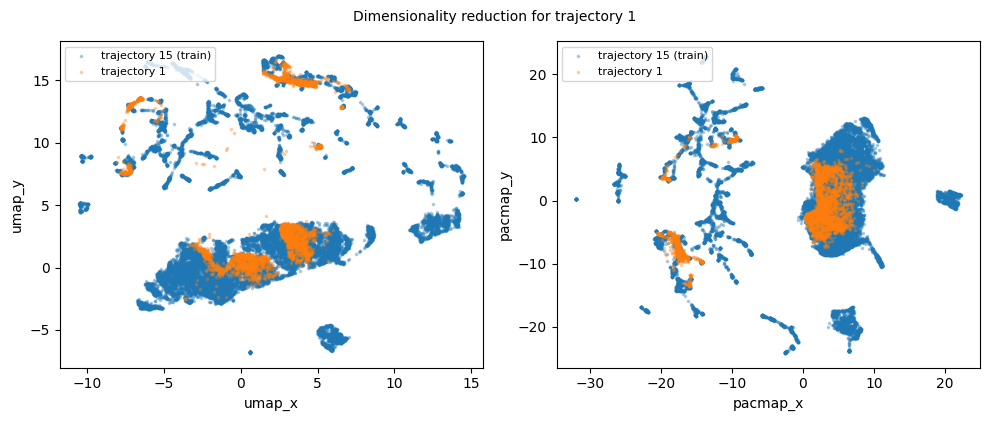

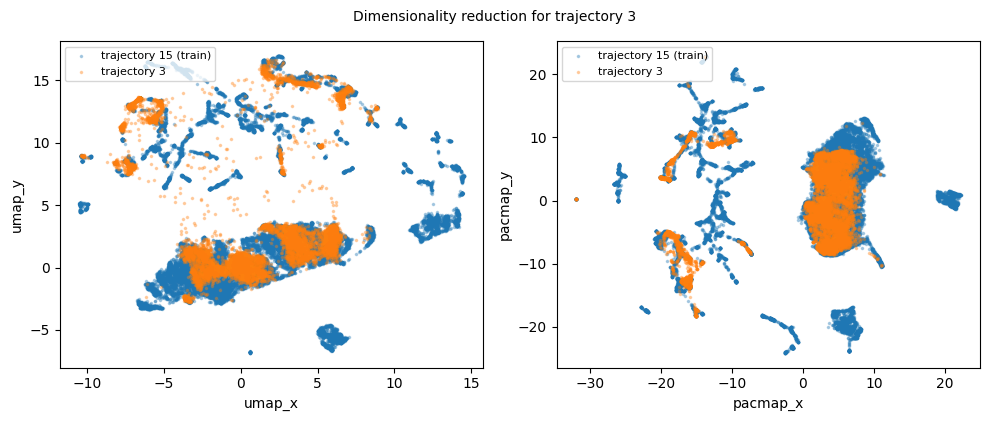

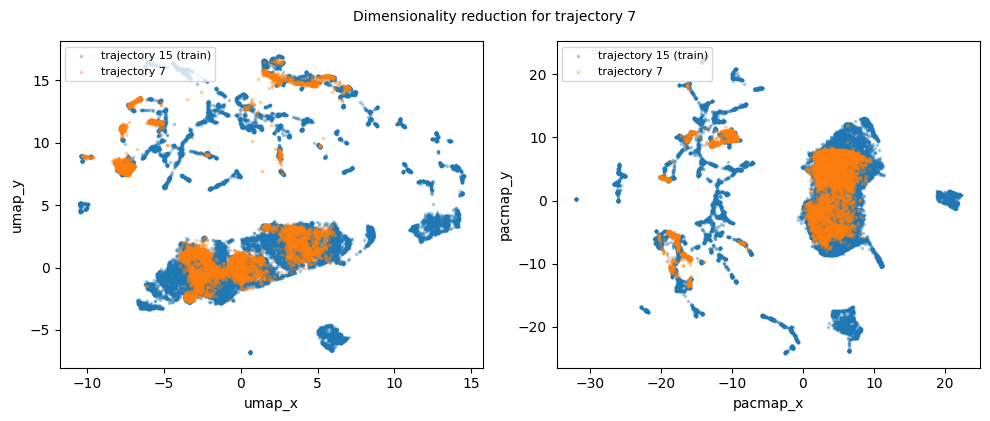

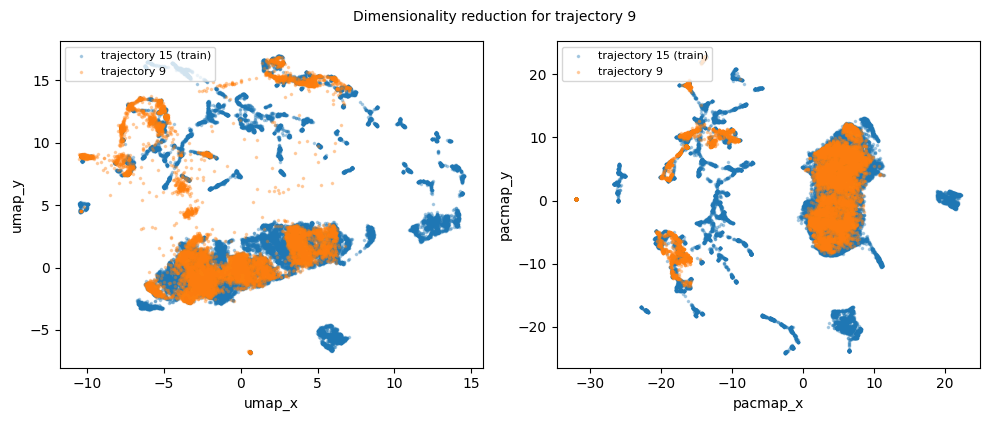

In [8]:
Clusters.plotEmbedding(nfigures=4)

### Comparison of clusters by dimensionality reduction algorithm

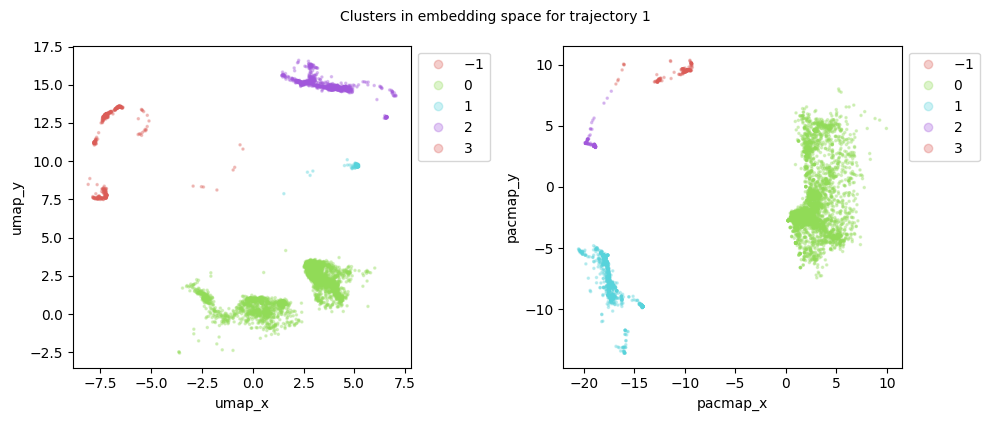

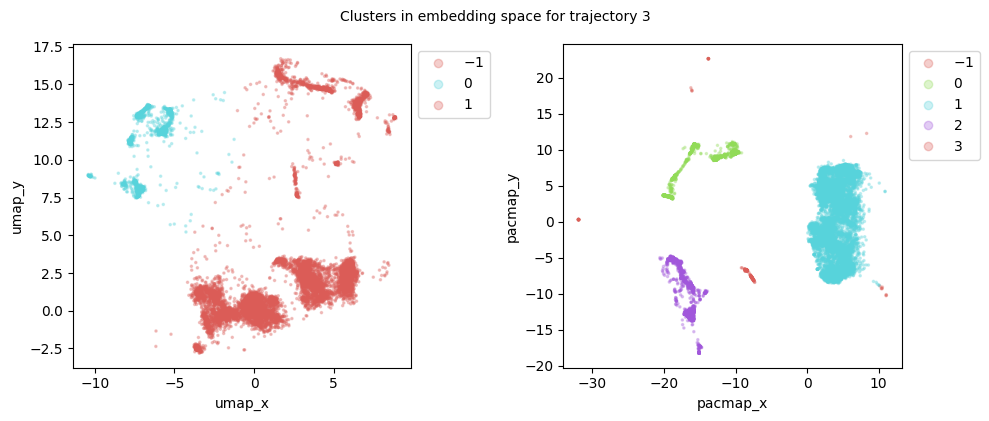

In [9]:
Clusters.plotResults(nfigures=2)

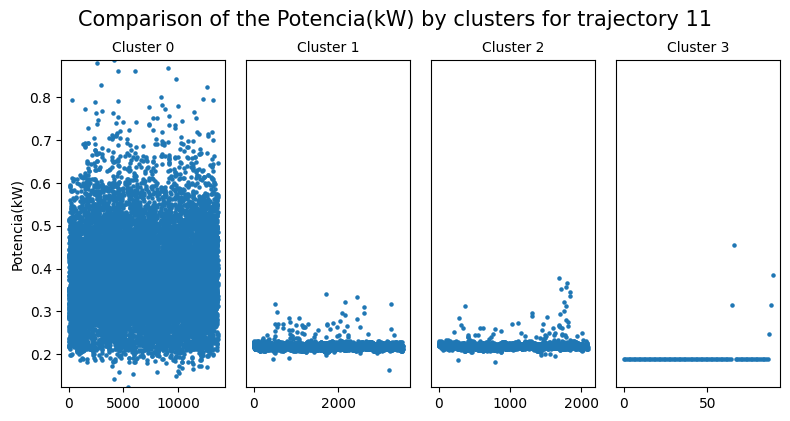

In [10]:
variable = dfManipulableVar.columns[2]
Clusters.plotVarByCluster(idxTrajectory = 4, 
                          variable      = variable, 
                          algorithm     = 'pacmap')

### Clusters in embedding space

In [11]:
Clusters.plotFigure('scatter2D', 
                    idxTrajectory   = 5, 
                    idxVariable     = 10, 
                    algorithm       = 'pacmap')

### Time series colored by clusters

In [12]:
Clusters.plotFigure('lineplot', 
                    idxTrajectory   = 1, 
                    idxVariable     = 0, 
                    algorithm       = 'pacmap')

# Clusters Comparison

In [14]:
dfSimilarclusters = Clusters.getSimilarClusters(algorithm = 'pacmap', 
                                                threshold = 5)

In [26]:
idxGroupCluster = 10
scatterPlot2D(data  = dfSimilarclusters[dfSimilarclusters['group']==idxGroupCluster], 
              x     = 'pacmap_x', 
              y     = 'pacmap_y', 
            #  z     = 'pacmap_z', 
              color = 'label',
              title = 'Similar clusters')

In [24]:
Clusters.trajectories

array(['1', '3', '7', '9', '11', '15', '17', '19', '21', '23', '25', '27',
       '29', '37', '39', '41', '45', '49', '51', '55', '61', '63', '65',
       '67', '71'], dtype=object)

In [25]:
# Clusters.plotFigure('lineplot', 
#                     idxTrajectory=2, 
#                     idxVariable=0, 
#                     algorithm='pacmap')

In [ ]:
# Clusters.plotFigure('lineplot', 
#                     idxTrajectory=0, 
#                     idxVariable=0, 
#                     algorithm='pacmap')